# 01 — EDA (TV1, Việc 4)

**Add Input:** Kaggle Dataset `nhom05-falldet-processed` (tạo từ `00_prepare_data.ipynb`). Bật **Internet**, không cần GPU.

**Trước khi chạy:** code mới nhất đã được commit và push lên nhánh `tv1/gk-data-eda-m1`.

Đầu ra: các biểu đồ `eda_*.png` trong `reports/figures/` (dpi 200), bảng và số đo trong `reports/results/`, hình minh họa augmentation, và `DATA_CARD.md` có thêm khối kích thước khung hình.

In [1]:
# Ô đầu tiên: lấy mã nguồn, cố định seed, in version Python, torch, ultralytics, opencv và version dataset.
# Cần bật Internet để clone repo. Nếu thư mục đã có (chạy lại trong cùng phiên) thì pull để lấy code mới.
import os, sys
BRANCH = "main"  # đổi thành "main" sau khi PR #2 được merge
REPO = "/kaggle/working/FallDetection"
if not os.path.exists(REPO):
    !git clone --depth 1 -b {BRANCH} https://github.com/ducqwang/FallDetection.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
!pip install -q ultralytics==8.4.202 lap==0.5.14
sys.path.insert(0, REPO)
from src.data.env_info import setup_notebook
setup_notebook("configs/data.yaml", seed=42)

Cloning into '/kaggle/working/FallDetection'...
remote: Enumerating objects: 102, done.
remote: Counting objects: 100% (102/102), done.
remote: Compressing objects: 100% (94/94), done.
remote: Total 102 (delta 5), reused 61 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (102/102), 280.48 KiB | 5.97 MiB/s, done.
Resolving deltas: 100% (5/5), done.
/kaggle/working/FallDetection
seed = 42 | Python 3.13.16
torch: 2.11.0+cu130
ultralytics: 8.4.202
opencv: 4.14.0
dataset urfd_images: https://www.kaggle.com/datasets/shahliza27/ur-fall-detection-dataset | version: 1
dataset urfd_labels: https://www.kaggle.com/datasets/minhquang2701/urfall-labels | version: 1
dataset le2i: https://www.kaggle.com/datasets/tuyenldvn/falldataset-imvia | version: 2


In [2]:
from pathlib import Path
from src.data.loader import data_root, load_metadata
ROOT = data_root()
print("Dữ liệu:", ROOT)
meta = load_metadata(ROOT)
print(meta.groupby(["dataset", "scene"]).size())

Dữ liệu: /kaggle/input/notebooks/minhquang2701/nhom05-falldet-processed/nhom05-falldet-processed
dataset  scene      
le2i     coffee_room    70
         home           60
urfd     urfd           70
dtype: int64


## Biểu đồ EDA

Biểu đồ 1–4 chỉ đọc `metadata.csv`. Biểu đồ 5 dùng đặc trưng hình học theo cửa sổ từ Le2i GT bbox, vẽ hai bản: 5 tô theo lớp, 5b tô theo kích thước khung (320×180 / 320×240). Biểu đồ 6 và `reports/results/le2i_scene_size_table.csv` là bảng scene × kích thước × lớp. Khối cảnh báo kích thước được ghi vào `DATA_CARD.md` (không có `--data-card` thì bỏ qua). Khi có tracks cache, thêm `--tracks <đường dẫn>`.

In [3]:
# Lấy DATA_CARD.md đầy đủ do prepare_data sinh ra, để EDA chỉ ghi thêm khối kích thước vào đó (không tạo file rỗng).
!cp {ROOT}/DATA_CARD.md DATA_CARD.md
!python -m src.eda.plots --meta {ROOT}/metadata.csv --gt-bbox {ROOT}/annotations/le2i_gt_bbox.csv --out-dir reports/figures --window-s 1.0 --stride-s 0.25 --perplexity 30 --seed 42 --results-dir reports/results --data-card DATA_CARD.md

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/kaggle/working/FallDetection/src/eda/plots.py", line 193, in <module>
    main()
    ~~~~^^
  File "/kaggle/working/FallDetection/src/eda/plots.py", line 168, in main
    X, y, names, sizes = build_window_features(boxes, meta, args.window_s, args.stride_s, config["signals"],
                         ~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                                               config["rules"]["still_speed"], gt_boxes if args.tracks else None, with_size=True)
                                               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/kaggle/working/FallDetection/src/eda/window_features.py", line 68, in build_window_features
    vectors, labels = video_windows(track, row, window_s, stride_s, signal_params, still_speed)
         

eda_1_clip_counts.png


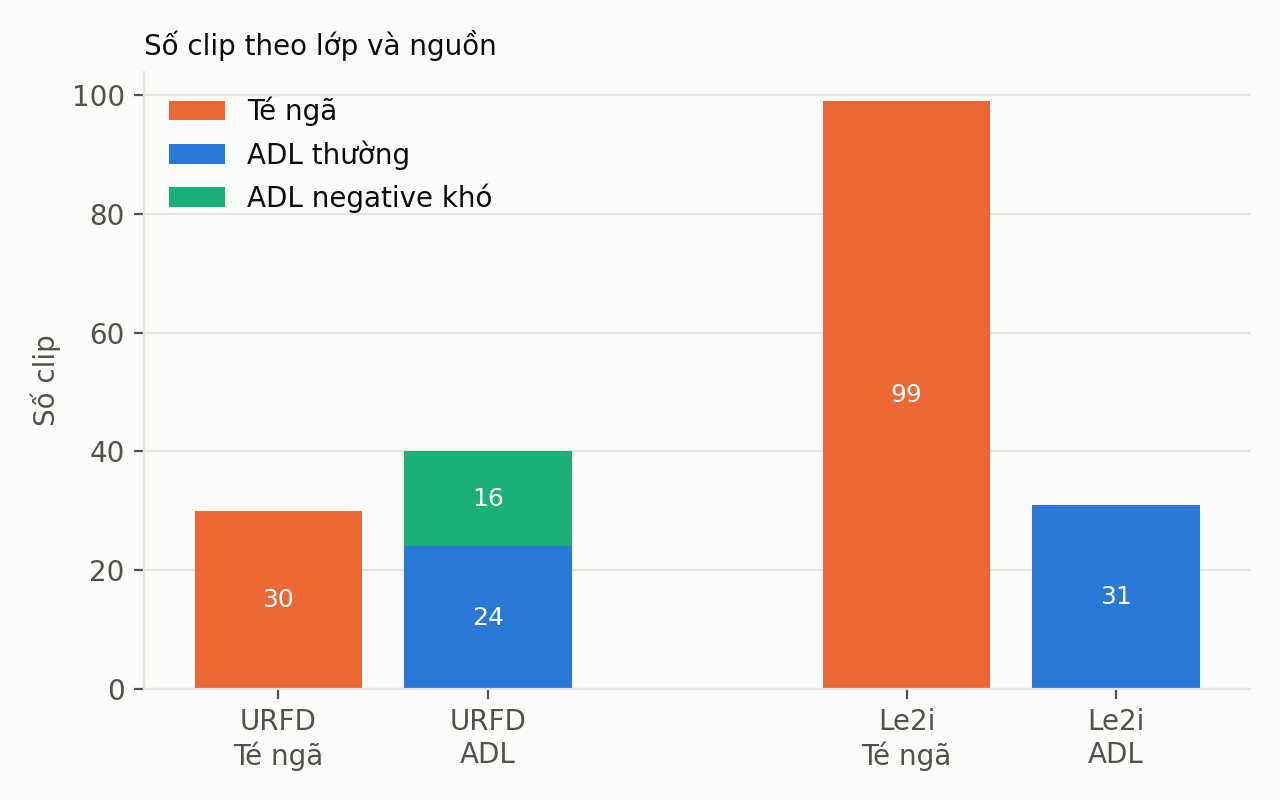

eda_2_duration.png


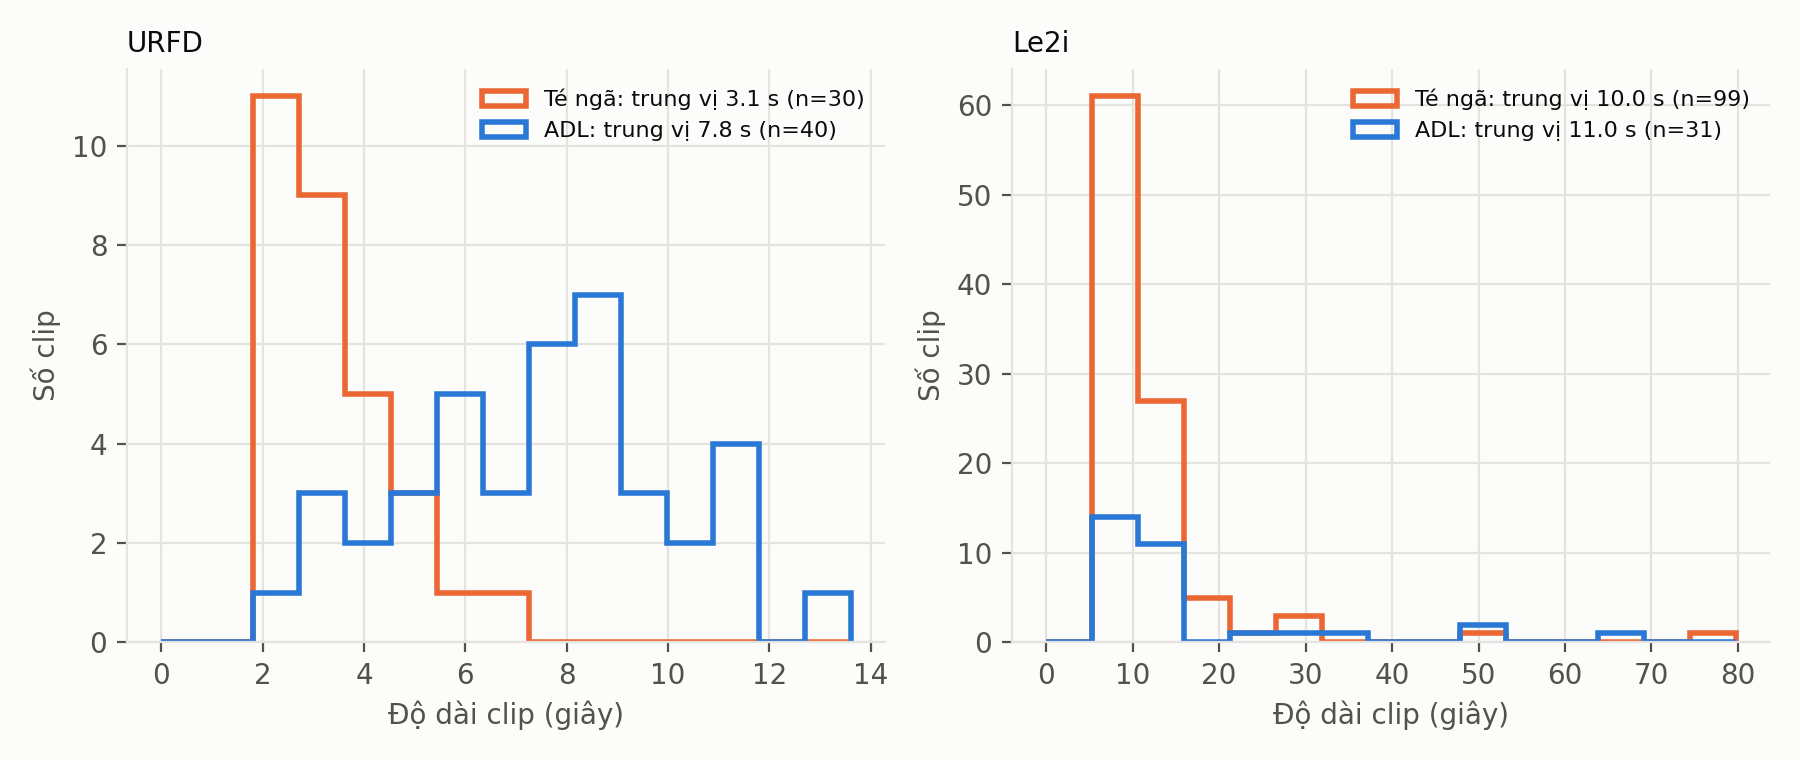

eda_3_frame_balance.png


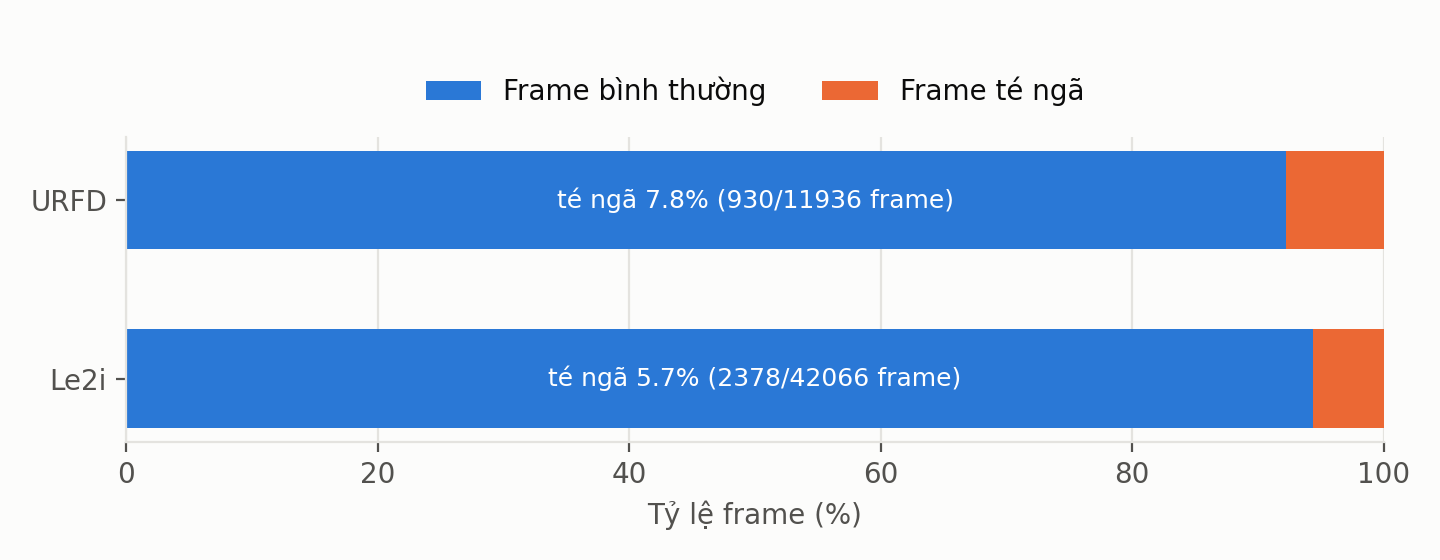

eda_4_scene_distribution.png


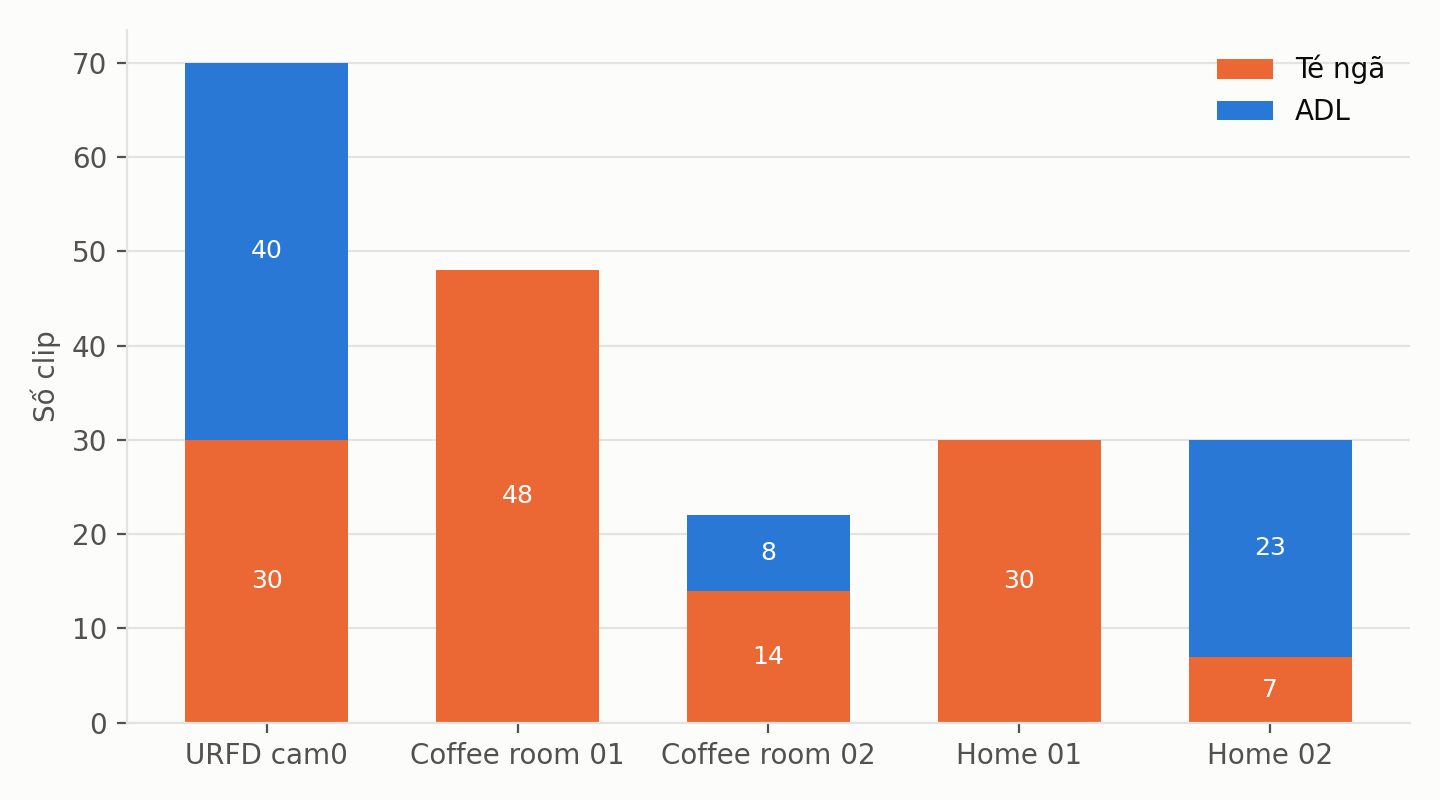

FileNotFoundError: [Errno 2] No such file or directory: 'reports/results/le2i_scene_size_table.csv'

In [4]:
from IPython.display import Image, display
import pandas as pd
for path in sorted(Path("reports/figures").glob("eda_*.png")):
    print(path.name)
    display(Image(str(path), width=720))
display(pd.read_csv("reports/results/le2i_scene_size_table.csv", dtype={"scene_part": str}))
print(Path("reports/results/size_separation.json").read_text())


## Hình minh họa tăng cường dữ liệu

In [ ]:
from src.data.augment import save_augment_preview
from src.data.loader import read_frames
row = meta[(meta["dataset"] == "urfd") & (meta["label"] == "fall")].iloc[0]
start = int(row["fall_start_frame"])
clip = read_frames(row["video_id"], start, start + 30, root=ROOT)
path = save_augment_preview(clip, "reports/figures/augment_demo.png")
display(Image(str(path), width=720))

Chạy xong, tải từ tab Output (thư mục `FallDetection`): `reports/figures/*.png` và `reports/results/*` commit vào `reports/` của repo; `DATA_CARD.md` (đã đủ nội dung dataset và khối kích thước) commit vào `dataset_index/`.